# Jev_CeNN — CUDA-Optimized Hybrid Cellular + Attention (30 Layers)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vtavakkoli/TinyCeNN-LM/blob/main/notebooks/Jev_CeNN_CUDA_Fast_AllAttention_Colab.ipynb)

## What this notebook changes from Laya V3.1

**Official model family: Jev_CeNN** (trained from the original Laya *teacher*, but the resulting student is independently named).

- **Preserves the same 30 trained replacement modules and checkpoint shapes**: 10 global FastWindowMemory + 20 SlidingWindowFusion; full-model jointly fine-tuned; independent held-out TEST and HF export remain.
- **New real CUDA code:** stride-aware Triton softmax sliding attention processes **one query and its ±64 neighbors** without building temporary halo/unfold masks; **no attention is approximated**. One kernel call replaces the blocked local SDPA implementation for inference only. The differentiable reference path remains for training.
- **Validated kernel selection:** Before enabling the backend, several lengths (including 9, 129, 290, 512), padding cases and both FP16/BF16 when supported are checked against the original PyTorch implementation. Failure disables the fast path or fails preflight; never silently publish unvalidated numerical changes.
- **Shared all-layer teacher I/O cache:** One set of train/probe/audit teacher forward passes populates teacher outputs for all 30 layers instead of up to 30 independent sets. CPU FP16 storage + per-layer GPU promotion. Disable if RAM is limited.
- **Reduce heavy cumulative full-model DEV evaluations** from 30 to every 5 layers by default. Every candidate still receives its own disjoint local probe and audit.
- **Benchmark** original vs optimized per-attention kernel and full-model end-to-end CUDA performance, on your GPU. Optional `torch.compile` inference benchmark can be enabled; it does not alter saved weights.
- **Portable Jev_CeNN HF bundle:** A fully standalone runtime includes the optional Triton kernel, CPU fallback, checkpoint/loader, tokenizer and reproducible evaluation metadata; no project-library dependency required.

**Scientific caveat:** global W1024 is still quadratic full-context attention for MAX_LEN512 and sliding W129 remains attention. Kernel speed is **not guaranteed** on all GPUs or sequence lengths. Numerical parity and actual measurements decide. The 0.99 quality gates still apply. This Colab does not claim new training or performance scores until you run it.

**Memory note:** Shared training caches require several gigabytes of Colab RAM on the 30-layer encoder; turn off SHARED_TEACHER_CACHE if memory is insufficient.

**Publishing:** `PUBLISH_TO_HF=True` and `HF_PRIVATE=True` by default. Add `HF_TOKEN` in Colab Secrets; upload happens only after held-out DEV gates + standalone strict weight and output parity. No upload during GitHub CI.


In [1]:
#@title 1. Install Jev_CeNN CUDA and training dependencies
%pip -q install "transformers==4.57.6" "datasets>=2.20,<5" "triton>=3.0,<4" "huggingface_hub>=0.25,<1" "safetensors>=0.4"
%pip -q install -U "git+https://github.com/vtavakkoli/TinyCeNN-LM.git@main"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 48.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 46.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
#@title 2. Jev_CeNN configuration: GPU speed, accuracy, fine-tuning, Hub
from pathlib import Path
import copy, json, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub import snapshot_download
from transformers import AutoTokenizer
from transformers.models.modernbert.modeling_modernbert import apply_rotary_pos_emb
from tinycenn_lm.laya_lab.pdelta import PDelta3GDN2CLVRAttention
from tinycenn_lm.laya_lab.core import _depthwise_sequence_conv, _valid_tokens
from tinycenn_lm.standalone_decision import (
    QTYPES, build_checkpoint_model, build_sequence, collate_items,
    normalize_question,
)
from tinycenn_lm.decision_training import require_finite, decision_distill_loss, guarded_step
from tinycenn_lm.sliding_window_fusion import SlidingWindowFusion

SEED = 2028
SOURCE_MODEL = "convaiinnovations/laya-typed-decisions" #@param {type:"string"}
LAYER = 15 # set explicitly per global layer
FULL_WINDOW = 1024 #@param {type:"integer"}
SLIDING_RADIUS = 64 #@param {type:"integer"}
SLIDING_BLOCK_SIZE = 64 #@param {type:"integer"}
LANDMARK_STRIDE = 16
FEATURE_DIM = 96
MAX_LANDMARKS = 32
TRAIN_CASES = 600 #@param {type:"integer"}
DEV_CASES = 180 #@param {type:"integer"}
MAX_LEN = 512 #@param {type:"integer"}
BATCH = 2 #@param {type:"integer"}
GLOBAL_STEPS = 400 #@param {type:"integer"}
SLIDING_STEPS = 250 #@param {type:"integer"}
JOINT_STEPS = 160 #@param {type:"integer"}
JOINT_BATCH = 1
JOINT_DEV_LIMIT = 160
CHECK_EVERY = 50
TRAIN_CACHE_BATCHES = 32 #@param {type:"integer"}
PROBE_CACHE_BATCHES = 8 #@param {type:"integer"}
AUDIT_CACHE_BATCHES = 8 #@param {type:"integer"}
TARGET_COSINE = 0.99
TARGET_NMSE = 0.025
TARGET_DEV_AGREEMENT = 0.99
MAX_GOLD_DROP = 0.015
MAX_AGREEMENT_DROP_AFTER_TUNE = 0.005
SUPERVISED_WEIGHT = 0.15 #@param {type:"number"}
TEACHER_WEIGHT = 0.5 #@param {type:"number"}
FINE_TUNE_TASK_HEAD = True #@param {type:"boolean"}
USE_V29_CHECKPOINT = False #@param {type:"boolean"}
V29_CHECKPOINT = "/content/Laya_V29_AllGlobal_FastWindowMemory/v29_all_global_W1024.pt" #@param {type:"string"}
USE_V30_SLIDING_CHECKPOINTS = False #@param {type:"boolean"}
V30_SLIDING_DIR = "/content/Laya_V30_SlidingFusion/layers_W129" #@param {type:"string"}
PUBLISH_TO_HF = True #@param {type:"boolean"}
PUBLISH_ONLY_IF_PASSES = True #@param {type:"boolean"}
HF_PRIVATE = True #@param {type:"boolean"}
HF_REPO_ID = "" #@param {type:"string"}
USE_TRITON_CUDA = True #@param {type:"boolean"}
STRICT_KERNEL_PARITY = True #@param {type:"boolean"}
SHARED_TEACHER_CACHE = True #@param {type:"boolean"}
DEV_EVAL_EVERY_LAYERS = 5 #@param {type:"integer"}
TRY_TORCH_COMPILE_INFERENCE = False #@param {type:"boolean"}

OUTPUT_DIR = Path("/content/Jev_CeNN")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
STEPS = GLOBAL_STEPS
assert GLOBAL_STEPS > 0 and SLIDING_STEPS > 0 and JOINT_STEPS >= 0
assert BATCH >= 1 and 0 <= SLIDING_RADIUS <= 64
assert MAX_LEN >= 128 and FULL_WINDOW >= 32
assert DEV_EVAL_EVERY_LAYERS >= 1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("This notebook needs a CUDA GPU (Colab > Runtime > Change runtime type).")
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda")
amp_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16

source_dir = Path(snapshot_download(
    SOURCE_MODEL,
    allow_patterns=["rl_agent_config.json", "model.safetensors", "encoder/*", "tokenizer/*"],
))
teacher, source_cfg = build_checkpoint_model(source_dir)
student_eval, _ = build_checkpoint_model(source_dir)
tokenizer = AutoTokenizer.from_pretrained(str(source_dir / "tokenizer"))
teacher.to(device).eval().requires_grad_(False)
student_eval.to(device).eval().requires_grad_(False)
teacher.encoder.config.reference_compile = False
student_eval.encoder.config.reference_compile = False

print("GPU:", torch.cuda.get_device_name(0), "| AMP:", amp_dtype)
from tinycenn_lm.standalone_decision import full_attention_indices
GLOBAL_LAYERS = full_attention_indices(teacher)
SLIDING_LAYERS = [i for i in range(len(teacher.encoder.layers)) if i not in GLOBAL_LAYERS]
assert GLOBAL_LAYERS and 15 in GLOBAL_LAYERS and len(GLOBAL_LAYERS)+len(SLIDING_LAYERS)==len(teacher.encoder.layers)
for i in GLOBAL_LAYERS:
    assert tuple(teacher.encoder.layers[i].attn.local_attention) == (-1, -1)
print("Global layers:", GLOBAL_LAYERS, "| native sliding:", SLIDING_LAYERS)
print("Global W:", FULL_WINDOW, "| sliding W:", 2*SLIDING_RADIUS+1, "| MAX_LEN:", MAX_LEN)
assert all(tuple(teacher.encoder.layers[i].attn.local_attention) == (64,64) for i in SLIDING_LAYERS), "Adjust SLIDING_RADIUS if native model sliding radius changes"
print("W>=2*MAX_LEN-1 gives dense full-context local attention:", FULL_WINDOW >= 2*MAX_LEN-1)
print("Teacher:", SOURCE_MODEL, "| official test split stays untouched")


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/337 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

rl_agent_config.json:   0%|          | 0.00/847 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/843M [00:00<?, ?B/s]

GPU: Tesla T4 | AMP: torch.float16
Global layers: [0, 3, 6, 9, 12, 15, 18, 21, 24, 27] | native sliding: [1, 2, 4, 5, 7, 8, 10, 11, 13, 14, 16, 17, 19, 20, 22, 23, 25, 26]
Global W: 1024 | sliding W: 129 | MAX_LEN: 512
W>=2*MAX_LEN-1 gives dense full-context local attention: True
Teacher: convaiinnovations/laya-typed-decisions | official test split stays untouched


In [3]:
#@title 3. Leak-free train/dev data and teacher I/O helpers
def _jsonish(x):
    if isinstance(x, str):
        try:
            return json.loads(x)
        except Exception:
            return x
    return x

def _canon_label(x):
    s = str(x).strip().lower()
    try:
        v = float(s)
        if math.isfinite(v) and v.is_integer():
            return str(int(v))
    except Exception:
        pass
    return s

def _gold_metadata(q, gold_answer):
    if not isinstance(gold_answer, dict):
        raise ValueError("missing gold answer")
    probs_raw = _jsonish(gold_answer.get("probabilities", {}))
    if not isinstance(probs_raw, dict) or len(probs_raw) < 2:
        raise ValueError("gold probabilities missing or malformed")

    gold_keys = [str(k) for k in probs_raw.keys()]
    if q["t"] == "choice":
        labels = [str(k) for k in q["crit"].keys()]
    elif q["t"] == "noul":
        labels = ["false", "true"]
    else:
        labels = list(gold_keys)
        if all(_canon_label(k).lstrip("-").isdigit() for k in labels):
            labels = sorted(labels, key=lambda k: int(_canon_label(k)))

    lookup = {_canon_label(k): float(v) for k, v in probs_raw.items()}
    if len(labels) != len(gold_keys) or any(_canon_label(k) not in lookup for k in labels):
        raise ValueError("Gold labels do not match encoded option order")

    gold_probs = np.asarray([lookup[_canon_label(k)] for k in labels], dtype=np.float64)
    gold_probs = np.clip(gold_probs, 0.0, None)
    if not np.isfinite(gold_probs).all() or gold_probs.sum() <= 0:
        raise ValueError("invalid gold probability vector")
    gold_probs /= gold_probs.sum()

    gold_label = _canon_label(gold_answer.get("label", labels[int(gold_probs.argmax())]))
    canon_labels = [_canon_label(k) for k in labels]
    if gold_label not in canon_labels:
        raise ValueError(f"gold label {gold_label!r} not in {labels!r}")
    return labels, gold_probs.tolist(), canon_labels.index(gold_label)

def make_items_from_rows(rows, seed, shuffle_items):
    out = []
    head_max_len = int(source_cfg.get("head_max_len", 192))
    for row in rows:
        state = _jsonish(row["state"])
        questions = _jsonish(row["questions"])
        gold = _jsonish(row["gold"])
        case_id = str(row.get("id", ""))
        workflow = str(row.get("workflow", "unknown"))
        state_text = state if isinstance(state, str) else json.dumps(state, ensure_ascii=False)
        state_ids = tokenizer(
            state_text.replace(tokenizer.mask_token, " "),
            add_special_tokens=False,
        )["input_ids"]

        for qid, qdef in questions.items():
            q = normalize_question(qdef)
            ids, markers = build_sequence(
                tokenizer,
                state,
                q,
                max_len=min(MAX_LEN, int(source_cfg.get("max_len", MAX_LEN))),
                head_max_len=head_max_len,
                truncate_left=isinstance(state, list),
                state_ids=state_ids,
            )
            if len(markers) < 2:
                continue
            labels, gold_probs, gold_index = _gold_metadata(q, gold[qid])
            if len(labels) != len(markers):
                raise ValueError(
                    f"{case_id}/{qid}: {len(markers)} markers vs {len(labels)} gold labels"
                )
            out.append({
                "ids": ids,
                "markers": markers,
                "qtype": QTYPES[q["t"]],
                "qtype_name": q["t"],
                "qid": str(qid),
                "case_id": case_id,
                "workflow": workflow,
                "labels": labels,
                "gold_probs": gold_probs,
                "gold_index": int(gold_index),
            })
    if shuffle_items:
        random.Random(seed).shuffle(out)
    return out

rows = list(load_dataset("LocalLLaMA/typed-decisions", "all", split="train"))
rng = random.Random(SEED)
rng.shuffle(rows)
assert TRAIN_CASES + DEV_CASES <= len(rows)
train_rows = rows[:TRAIN_CASES]
dev_rows = rows[TRAIN_CASES:TRAIN_CASES + DEV_CASES]
train_items = make_items_from_rows(train_rows, SEED, True)
dev_items = make_items_from_rows(dev_rows, SEED + 1, True)

def direct_batch(selected):
    b = collate_items(selected, int(tokenizer.pad_token_id))
    return {k: v.to(device) for k, v in b.items()}

def batch(items, offset, n=BATCH):
    selected = [items[(offset + i) % len(items)] for i in range(n)]
    return direct_batch(selected)

def attn_io(model, layer_idx, b):
    layer = model.encoder.layers[layer_idx]
    got = {}
    def pre(mod, args, kwargs):
        got["x"] = args[0].detach()
        got["pos"] = None if kwargs.get("position_embeddings") is None else tuple(
            z.detach() for z in kwargs["position_embeddings"]
        )
        got["mask"] = None if kwargs.get("attention_mask") is None else kwargs["attention_mask"].detach()
        # ModernBERT SDPA requires position_ids and sliding_window_mask.
        # Replay the exact teacher call, including all positional/mask kwargs.
        got["call_kwargs"] = {
            key: (value.detach() if torch.is_tensor(value) else value)
            for key, value in kwargs.items()
        }
        if "position_ids" not in got["call_kwargs"] or "sliding_window_mask" not in got["call_kwargs"]:
            raise RuntimeError("Teacher attention hook did not capture ModernBERT SDPA kwargs")
    def post(mod, args, kwargs, out):
        got["y"] = out[0].detach()
    h1 = layer.attn.register_forward_pre_hook(pre, with_kwargs=True)
    h2 = layer.attn.register_forward_hook(post, with_kwargs=True)
    try:
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=amp_dtype):
            model(**b)
    finally:
        h1.remove()
        h2.remove()
    return got

def cache_teacher_io(layer_idx, items, batches, offset=0):
    cache = []
    for i in range(batches):
        b = batch(items, offset + i * BATCH, BATCH)
        got = attn_io(teacher, layer_idx, b)
        cache.append({
            "x": got["x"],
            "pos": got["pos"],
            "mask": got["mask"],
            "call_kwargs": got["call_kwargs"],
            "y": got["y"],
            "valid": b["attention_mask"].bool(),
        })
    return cache

def local_metrics_from_cache(repl, cache):
    repl.eval()
    diff_sum = power_sum = cos_sum = 0.0
    tokens = 0
    with torch.no_grad():
        for entry in cache:
            with torch.autocast(device_type="cuda", dtype=amp_dtype):
                pred = repl(entry["x"], **entry["call_kwargs"])[0]
            require_finite(pred, "all-attention local probe")
            valid = entry["valid"]
            m = valid[:, :, None].float()
            d = pred.shape[-1]
            diff_sum += float((((pred.float() - entry["y"].float()) ** 2) * m).sum())
            power_sum += float(((entry["y"].float() ** 2) * m).sum())
            count = int(valid.sum())
            cos_sum += float(
                F.cosine_similarity(
                    pred.float()[valid],
                    entry["y"].float()[valid],
                    dim=-1,
                ).sum()
            )
            tokens += count
    nmse = diff_sum / max(power_sum, 1e-8)
    cosine = cos_sum / max(tokens, 1)
    score = nmse + 1.10 * (1.0 - cosine)
    return {"nmse": nmse, "cosine": cosine, "score": score, "tokens": tokens}

print("train/dev decisions:", len(train_items), len(dev_items))
assert len(dev_items) >= BATCH * (PROBE_CACHE_BATCHES + AUDIT_CACHE_BATCHES), "Increase DEV_CASES for disjoint probe and audit caches"
print("official test remains untouched; probe/audit I/O non-overlapping")


README.md: 0.00B [00:00, ?B/s]

all/train-00000-of-00001.parquet:   0%|          | 0.00/599k [00:00<?, ?B/s]

all/test-00000-of-00001.parquet:   0%|          | 0.00/222k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400 [00:00<?, ? examples/s]

train/dev decisions: 3000 900
official test remains untouched; probe/audit I/O non-overlapping


In [4]:
#@title 4. Global replacement: pretrained RoPE, local W + 32 capped landmarks and linear memory
class PDeltaV28FastWindowMemory(PDelta3GDN2CLVRAttention):
    """PDelta3-inspired replacement without sequential GDN scan.

    Complexity: local attention O(T*W*d), landmark cross attention
    O(T*ceil(T/stride)*d), and kernel memory O(T*F*d).
    The landmark branch becomes quadratic if stride is fixed while T -> infinity.
    For provably bounded linear scaling, cap its count with adaptive pooling.
    """
    architecture = "pdelta_v28_fast_window_memory"

    def __init__(self, original, *, local_window=96, landmark_stride=16,
                 feature_dim=96, max_landmarks=32):
        super().__init__(
            original, feature_dim=feature_dim, conv_kernel=4,
            chunk_size=32, local_kernel=5,
            local_window=local_window, local_gate_init=0.90,
        )
        self.landmark_stride = int(landmark_stride)
        self.max_landmarks = int(max_landmarks)
        assert self.landmark_stride > 0 and self.max_landmarks > 0
        # Remove obsolete recurrent, causal-convolution and four-way fusion parameters.
        # The inherited methods _local_attention and _global_linear remain in use.
        for name in (
            "wq", "wk", "decay_w", "dt_bias", "erase_w", "erase_b",
            "write_w", "write_b", "route_proj", "route_gate_w",
            "route_gate_b", "q_conv", "k_conv", "v_conv",
            "mix_logits", "mix_gate_w", "local_gate_w",
            "local_gate_b", "log_gain",
        ):
            delattr(self, name)
        # 4.57.6 passes position_ids to ModernBERT, not position_embeddings.
        # Copy the exact pretrained per-layer RoPE instead of silently skipping it.
        self.rotary_emb = copy.deepcopy(original.rotary_emb)
        self.rotary_emb.requires_grad_(False)
        self.layer_idx = int(getattr(original, "layer_id", -1))
        h, d = self.num_heads, self.head_dim
        # [local, compressed landmarks, global linear, direct value].
        # Layer 15 is global: do not initialize with ~90% exclusively local routing.
        self.route_logits = nn.Parameter(
            torch.tensor([1.0, 0.2, 0.2, -2.2]).repeat(h, 1)
        )
        self.route_query = nn.Parameter(torch.zeros(h, 4, d))
        self.local_log_temperature = nn.Parameter(torch.zeros(h))
        self.landmark_log_temperature = nn.Parameter(torch.zeros(h))
        self.conv_gain = nn.Parameter(torch.full((h,), -4.0))
        # Pretrained QKV and Wo are copied from the teacher by BaseLayaReplacementAttention.
        # Freeze QKV and allow a very small Wo calibration.
        for p in self.Wqkv.parameters():
            p.requires_grad_(False)
        for p in self.Wo.parameters():
            p.requires_grad_(True)

    def _local_attention(self, q, k, v, valid):
        """Centered local window; avoid huge empty W×(2W-1) halos when W >= T."""
        b, h, t, d = q.shape
        w = self.local_window
        if w < t:
            return super()._local_attention(q, k, v, valid)
        allowed = valid[:, None, None, :]
        if w < 2*t-1:
            qi = torch.arange(t, device=q.device)[:, None]
            ki = torch.arange(t, device=q.device)[None, :]
            band = ((ki >= qi-(w-1)//2) & (ki <= qi+w//2))
            allowed = allowed & band[None, None]
        z = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, dropout_p=0.0)
        return z * valid[:, None, :, None].to(z.dtype)

    def _landmarks(self, q, k, v, valid):
        b, h, t, d = k.shape
        # Choose at most max_landmarks pooled key/value blocks. This ensures
        # O(T*M) with M <= max_landmarks at all sequence lengths.
        stride = max(self.landmark_stride, math.ceil(t / self.max_landmarks))
        blocks = math.ceil(t / stride)
        pad = blocks * stride - t
        mask = valid[:, None, :, None].to(k.dtype)
        packed_valid = F.pad(valid, (0, pad), value=False).reshape(b, blocks, stride)
        counts = packed_valid.sum(-1)
        divisor = counts.clamp_min(1).to(k.dtype)[:, None, :, None]
        kp = F.pad(k * mask, (0, 0, 0, pad)).reshape(b, h, blocks, stride, d)
        vp = F.pad(v * mask, (0, 0, 0, pad)).reshape(b, h, blocks, stride, d)
        pooled_k = kp.sum(3) / divisor
        pooled_v = vp.sum(3) / divisor
        allowed = (counts > 0)[:, None, None, :]
        temperature = self.landmark_log_temperature.clamp(-0.4, 0.4).exp()
        q_scaled = q * temperature[None, :, None, None]
        # Only T x M attention scores; never a dense T x T matrix.
        return F.scaled_dot_product_attention(
            q_scaled, pooled_k, pooled_v, attn_mask=allowed, dropout_p=0.0
        ) * mask

    def forward(self, hidden_states, position_embeddings=None,
                attention_mask=None, position_ids=None, sliding_window_mask=None,
                **kwargs):
        # Exact teacher QKV + RoPE path; apply rotary embeddings BEFORE attention.
        b, t, _ = hidden_states.shape
        qkv = self.Wqkv(hidden_states).reshape(b, t, 3, self.num_heads, self.head_dim)
        q, k, v = qkv.transpose(3, 1).unbind(dim=2)
        if position_embeddings is None:
            cos, sin = self.rotary_emb(qkv, position_ids=position_ids)
        else:
            cos, sin = position_embeddings
        q, k = apply_rotary_pos_emb(q, k, cos, sin)
        valid = _valid_tokens(attention_mask, hidden_states)
        mask = valid[:, None, :, None].to(v.dtype)
        q, k, v = q * mask, k * mask, v * mask
        temperature = self.local_log_temperature.clamp(-0.4, 0.4).exp()
        qlocal = q * temperature[None, :, None, None]
        local = self._local_attention(qlocal, k, v, valid)
        landmarks = self._landmarks(q, k, v, valid)
        global_linear = self._global_linear(q, k, v, mask) * mask
        qnorm = F.normalize(q, dim=-1)
        dynamic = torch.einsum("bhtd,hkd->bhtk", qnorm, self.route_query)
        mixture = torch.softmax(
            self.route_logits.to(q.dtype)[None, :, None, :] + dynamic,
            dim=-1
        )
        fused = (
            mixture[..., 0:1] * local
            + mixture[..., 1:2] * landmarks
            + mixture[..., 2:3] * global_linear
            + mixture[..., 3:4] * v
        )
        local_conv = _depthwise_sequence_conv(v, self.local_weight, causal=False)
        conv_weight = torch.sigmoid(self.conv_gain).to(v.dtype)[None, :, None, None]
        fused = (fused + conv_weight * (local_conv - v)) * mask
        return self.finish(fused, hidden_states)

    def config_dict(self):
        return dict(
            architecture=self.architecture, layer_idx=self.layer_idx,
            local_window=self.local_window, landmark_stride=self.landmark_stride,
            max_landmarks=self.max_landmarks, feature_dim=self.feature_dim,
            global_linear_memory=True, local_windowed_attention=True,
            dense_global_full_attention=self.local_window >= 2 * MAX_LEN - 1, recurrent_scan=False,
            rope_applied=True, upstream_sdpa_kwargs=True,
        )

def build_v28(window):
    return PDeltaV28FastWindowMemory(
        teacher.encoder.layers[LAYER].attn,
        local_window=int(window),
        landmark_stride=LANDMARK_STRIDE,
        max_landmarks=32,
        feature_dim=FEATURE_DIM,
    ).to(device)

def state_cpu(module):
    return {k: p.detach().cpu().clone() for k, p in module.state_dict().items()}

print("V2.8 architecture ready (no GDN scan; bounded local + 32 capped landmarks)")


V2.8 architecture ready (no GDN scan; bounded local + 32 capped landmarks)


In [5]:
#@title 5. Fidelity-constrained teacher distillation, CPU snapshot checkpoints
def score_local(m):
    return m["nmse"] + 1.50 * (1.0 - m["cosine"])

def optimizer_v28(model):
    core, output = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        (output if name.startswith("Wo.") else core).append(p)
    params = core + output
    opt = torch.optim.AdamW([
        {"params": core, "lr": 0.003, "base_lr": 0.003},
        {"params": output, "lr": 0.00008, "base_lr": 0.00008},
    ], betas=(0.9, 0.95), weight_decay=2e-4)
    return opt, params

def train_400(model, train_cache, probe_cache, window):
    optimizer, params = optimizer_v28(model)
    scaler = torch.amp.GradScaler("cuda", enabled=amp_dtype == torch.float16, init_scale=128.0)
    best_metrics = local_metrics_from_cache(model, probe_cache)
    best_score = score_local(best_metrics)
    best_step = 0
    best_state = state_cpu(model)
    history = [{"step": 0, **best_metrics}]
    successes, attempts = 0, 0
    print(f"W{window} step    0/{STEPS}: NMSE={best_metrics['nmse']:.5f} cosine={best_metrics['cosine']:.5f}")

    while successes < STEPS:
        if attempts > STEPS + 300:
            raise RuntimeError("Too many AMP overflow/skipped optimizer steps")
        # A moderate cosine decay + short warmup is more stable than PDelta's
        # former 1e-2 opening learning rate, especially with trainable temperature.
        warm = min(1.0, (successes + 1) / 15.0)
        decay = 0.15 + 0.85 * 0.5 * (1.0 + math.cos(math.pi * successes / STEPS))
        for group in optimizer.param_groups:
            group["lr"] = group["base_lr"] * warm * decay

        model.train()
        model.out_drop.eval()
        entry = train_cache[attempts % len(train_cache)]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=amp_dtype):
            output = model(entry["x"], **entry["call_kwargs"])[0]
            m = entry["valid"][:, :, None].float()
            target = entry["y"].float()
            pred = output.float()
            mse = (((pred - target) ** 2) * m).sum() / (m.sum() * pred.shape[-1]).clamp_min(1)
            power = ((target ** 2) * m).sum() / (m.sum() * pred.shape[-1]).clamp_min(1)
            nmse = mse / power.clamp_min(1e-8)
            cos = F.cosine_similarity(pred[entry["valid"]], target[entry["valid"]], dim=-1).mean()
            loss = nmse + 1.50 * (1.0 - cos)
        require_finite(loss, f"V28 W{window} training loss")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        attempts += 1
        if scaler.is_enabled() and scaler.get_scale() < old_scale:
            continue
        successes += 1
        if successes == 1 or successes % CHECK_EVERY == 0 or successes == STEPS:
            probe = local_metrics_from_cache(model, probe_cache)
            history.append({"step": successes, **probe})
            s = score_local(probe)
            if s < best_score:
                best_score, best_metrics, best_step = s, probe, successes
                best_state = state_cpu(model)
            print(
                f"W{window} step {successes:4d}/{STEPS}: "
                f"NMSE={probe['nmse']:.5f} cosine={probe['cosine']:.5f} "
                f"| best cosine={best_metrics['cosine']:.5f} @ {best_step}"
            )
    model.load_state_dict(best_state, strict=True)
    model.eval()
    return {
        "best_step": best_step, "best_probe": best_metrics,
        "attempts": attempts, "successful_updates": successes,
        "history": history,
    }


In [6]:
#@title 6. Holdout model validation and CUDA latency
@torch.no_grad()
def validate_pair(student, items=dev_items, limit=None):
    teacher.eval()
    student.eval()
    limit = len(items) if limit is None else min(int(limit), len(items))
    total = agree = teacher_gold = student_gold = 0
    js = []
    for off in range(0, limit, BATCH):
        chosen = items[off:min(off + BATCH, limit)]
        b = direct_batch(chosen)
        with torch.autocast(device_type="cuda", dtype=amp_dtype):
            tl, _ = teacher(**b)
            sl, _ = student(**b)
        require_finite(tl, "teacher validation logits")
        require_finite(sl, "V28 validation logits")
        allowed = b["marker_mask"].bool()
        tp = torch.softmax(tl.float().masked_fill(~allowed, -1e9), -1)
        sp = torch.softmax(sl.float().masked_fill(~allowed, -1e9), -1)
        gt = torch.tensor([row["gold_index"] for row in chosen], device=device)
        agree += int((tp.argmax(-1) == sp.argmax(-1)).sum())
        teacher_gold += int((tp.argmax(-1) == gt).sum())
        student_gold += int((sp.argmax(-1) == gt).sum())
        mid = 0.5 * (tp + sp)
        q = 0.5 * (tp * (tp.clamp_min(1e-8).log() - mid.clamp_min(1e-8).log())).sum(-1)
        q += 0.5 * (sp * (sp.clamp_min(1e-8).log() - mid.clamp_min(1e-8).log())).sum(-1)
        js.extend(q.cpu().tolist())
        total += len(chosen)
    return dict(
        decisions=total, agreement=agree / max(total, 1),
        mean_js=float(np.mean(js)),
        teacher_gold_accuracy=teacher_gold / max(total, 1),
        student_gold_accuracy=student_gold / max(total, 1),
    )

@torch.inference_mode()
def timed_attention(module, entry, warmup=5, repeats=15):
    module.eval()
    with torch.autocast(device_type="cuda", dtype=amp_dtype):
        for _ in range(warmup):
            module(entry["x"], **entry["call_kwargs"])
        torch.cuda.synchronize()
        ms = []
        for _ in range(repeats):
            start = time.perf_counter()
            module(entry["x"], **entry["call_kwargs"])
            torch.cuda.synchronize()
            ms.append((time.perf_counter() - start) * 1000)
    return float(np.median(ms))

def attention_coverage(cache, window):
    lengths = torch.cat([item["valid"].sum(-1).cpu() for item in cache]).numpy()
    # A centered W=96 attends only 47 tokens left and 48 right.
    # Length <= W alone does NOT guarantee all-to-all attention.
    full_context_limit = min((window - 1) // 2, window // 2) + 1
    return {
        "sequences": int(len(lengths)),
        "median_valid_tokens": float(np.median(lengths)),
        "max_valid_tokens": int(np.max(lengths)),
        "fraction_fully_covered_by_local_window": float(np.mean(lengths <= full_context_limit)),
        "full_context_length_limit": int(full_context_limit),
        "sequences_longer_than_window": int(np.sum(lengths > window)),
        "sequences_at_least_2x_window": int(np.sum(lengths >= 2 * window)),
    }



In [7]:
#@title 7. Triton CUDA kernel parity + GPU microbenchmark (safe inference fast path)
import tinycenn_lm.sliding_window_fusion as swf
from tinycenn_lm.jev_cenn_cuda import (
    fast_sliding_sdpa, install_fast_sliding_backend,
    uninstall_fast_sliding_backend, triton_available
)
KERNEL_PREFLIGHT={"enabled":bool(USE_TRITON_CUDA),
                  "available":bool(triton_available()),"cases":[],"passed":False}
_GPU_ACCELERATED=False
if USE_TRITON_CUDA and triton_available():
    try:
        with torch.inference_mode():
            for length in (9,129,290,512):
                for radius in (32,SLIDING_RADIUS):
                    width=64
                    if radius > 256: continue
                    # Interleaved q,k,v strides (same as original ModernBERT).
                    xyz=torch.randn(2,length,3,4,width,device="cuda",dtype=amp_dtype)
                    queries,keys,values=xyz.transpose(3,1).unbind(2)
                    validity=torch.ones((2,length),device="cuda",dtype=torch.bool)
                    validity[1, max(1,length-5):]=False
                    truth=swf.local_sliding_sdpa(
                        queries,keys,values,validity,radius=radius,block_size=64)
                    found=fast_sliding_sdpa(
                        queries,keys,values,validity,radius=radius,block_size=64,
                        reference=swf.local_sliding_sdpa)
                    valid=validity[:,None,:,None].expand_as(found)
                    diff=(truth.float()-found.float()).abs()
                    delta=float(diff[valid].max())
                    cos=float(F.cosine_similarity(
                        truth.float()[validity[:,None,:].expand(2,4,length)].reshape(-1,width),
                        found.float()[validity[:,None,:].expand(2,4,length)].reshape(-1,width),
                        dim=-1
                    ).mean())
                    if not (delta < (0.05 if amp_dtype==torch.bfloat16 else 0.025)
                            and cos > 0.999):
                        raise AssertionError(
                            f"kernel parity failed T={length},R={radius}: "
                            f"max={delta:.5f}, cos={cos:.6f}"
                        )
                    KERNEL_PREFLIGHT["cases"].append(
                        {"length":length,"radius":radius,"max_abs":delta,"cosine":cos})
        _GPU_ACCELERATED=install_fast_sliding_backend(swf)
        KERNEL_PREFLIGHT["passed"]=_GPU_ACCELERATED
        print("Jev_CeNN Triton sliding GPU parity: PASS",
              len(KERNEL_PREFLIGHT["cases"]),"cases")
    except Exception as exc:
        uninstall_fast_sliding_backend(swf)
        KERNEL_PREFLIGHT["error"]=str(exc)
        print("GPU fast-path REJECTED; reference local SDPA retained:",repr(exc))
        if STRICT_KERNEL_PARITY:
            raise
else:
    print("Triton unavailable/disabled; verified PyTorch SDPA remains enabled.")
print("GPU fast sliding enabled:",_GPU_ACCELERATED)


Jev_CeNN Triton sliding GPU parity: PASS 8 cases
GPU fast sliding enabled: True


In [8]:
#@title 8. Single-pass ALL-30-layer teacher target cache (major training acceleration)
# Original V3.1 executes up to 30 independent sets of teacher forward passes.
# Jev_CeNN captures ALL original-layer input/output activations per teacher
# forward, compresses them to CPU FP16, and promotes one layer at a time.
_original_single_layer_cache=cache_teacher_io
_shared_caches={}
def _on_cpu(value):
    if torch.is_tensor(value):
        z=value.detach().cpu()
        return z.half().contiguous() if z.is_floating_point() else z.contiguous()
    if isinstance(value,(tuple,list)):
        return type(value)(_on_cpu(x) for x in value)
    if isinstance(value,dict):
        return {k:_on_cpu(v) for k,v in value.items()}
    return value
def _on_gpu(value):
    if torch.is_tensor(value):
        return value.to(device,non_blocking=True)
    if isinstance(value,(tuple,list)):
        return type(value)(_on_gpu(x) for x in value)
    if isinstance(value,dict):
        return {k:_on_gpu(v) for k,v in value.items()}
    return value
def _capture_all_layers(items,steps,offset,name):
    tracked=sorted(GLOBAL_LAYERS+SLIDING_LAYERS)
    captured={i:[] for i in tracked}
    transient={}
    hooks=[]
    def mk_pre(i):
        def pre(module,args,kwargs):
            transient[i]={"x":args[0].detach(),"kwargs":kwargs}
        return pre
    def mk_post(i):
        def post(module,args,kwargs,result):
            transient[i]["y"]=result[0].detach()
        return post
    for i in tracked:
        mod=teacher.encoder.layers[i].attn
        hooks.append(mod.register_forward_pre_hook(mk_pre(i),with_kwargs=True))
        hooks.append(mod.register_forward_hook(mk_post(i),with_kwargs=True))
    try:
        for step in range(steps):
            transient.clear()
            b=batch(items,offset+step*BATCH)
            with torch.no_grad(),torch.autocast("cuda",dtype=amp_dtype):
                teacher(**b)
            assert len(transient)==len(tracked)
            # Shared kwargs/validity object per batch — no 30x copies.
            kwargs_cpu=_on_cpu(transient[tracked[0]]["kwargs"])
            valid_cpu=b["attention_mask"].detach().cpu().bool()
            for i in tracked:
                entry=transient[i]
                captured[i].append({
                    "x":_on_cpu(entry["x"]),"y":_on_cpu(entry["y"]),
                    "call_kwargs":kwargs_cpu,"valid":valid_cpu
                })
            if (step+1)%8==0 or step+1==steps:
                print(f"  {name}: teacher batches {step+1}/{steps}, "
                      f"cached {len(tracked)} layers each")
    finally:
        for h in hooks:h.remove()
        transient.clear()
    return captured
if SHARED_TEACHER_CACHE:
    print("Building shared CPU-compressed teacher cache; requires several GB RAM.")
    _shared_caches["train"]=_capture_all_layers(
        train_items,TRAIN_CACHE_BATCHES,0,"TRAIN")
    _shared_caches["probe"]=_capture_all_layers(
        dev_items,PROBE_CACHE_BATCHES,0,"PROBE")
    _shared_caches["audit"]=_capture_all_layers(
        dev_items,AUDIT_CACHE_BATCHES,PROBE_CACHE_BATCHES*BATCH,"AUDIT")
    print("Shared teacher passes complete; all-30-layer cache ready.")
def cache_teacher_io(layer_idx,items,batches,offset=0):
    if SHARED_TEACHER_CACHE:
        key=(
            "train" if items is train_items and batches==TRAIN_CACHE_BATCHES
              and offset==0 else
            "probe" if items is dev_items and batches==PROBE_CACHE_BATCHES
              and offset==0 else
            "audit" if items is dev_items and batches==AUDIT_CACHE_BATCHES
              and offset==PROBE_CACHE_BATCHES*BATCH else None
        )
        if key is not None:
            return [_on_gpu(entry) for entry in _shared_caches[key][layer_idx]]
    return _original_single_layer_cache(layer_idx,items,batches,offset=offset)


Building shared CPU-compressed teacher cache; requires several GB RAM.
  TRAIN: teacher batches 8/32, cached 28 layers each
  TRAIN: teacher batches 16/32, cached 28 layers each
  TRAIN: teacher batches 24/32, cached 28 layers each
  TRAIN: teacher batches 32/32, cached 28 layers each
  PROBE: teacher batches 8/8, cached 28 layers each
  AUDIT: teacher batches 8/8, cached 28 layers each
Shared teacher passes complete; all-30-layer cache ready.


In [9]:
#@title 9. Jev_CeNN: install 10 global-memory attention layers
DEV_QUALITY_ITEMS = dev_items[(PROBE_CACHE_BATCHES + AUDIT_CACHE_BATCHES) * BATCH:]
assert len(DEV_QUALITY_ITEMS) >= JOINT_DEV_LIMIT
GLOBAL_RESULTS = []
CUMULATIVE = []
GLOBAL_DIR = OUTPUT_DIR / f"global_W{FULL_WINDOW}"
GLOBAL_DIR.mkdir(exist_ok=True, parents=True)
base_quality = validate_pair(student_eval, DEV_QUALITY_ITEMS, limit=JOINT_DEV_LIMIT)
print("Original teacher baseline:", base_quality)
if USE_V29_CHECKPOINT:
    v29_path = Path(V29_CHECKPOINT)
    if not v29_path.is_file():
        raise FileNotFoundError(
            f"V2.9 checkpoint missing: {v29_path}. Copy checkpoint to Colab or "
            "set USE_V29_CHECKPOINT=False to train from scratch."
        )
    v29 = torch.load(v29_path, map_location="cpu", weights_only=True)
    assert v29["global_layers"] == GLOBAL_LAYERS and int(v29["window"]) == FULL_WINDOW
    assert "student_state" in v29, "V2.9 checkpoint needs full model state"
    for i in GLOBAL_LAYERS:
        LAYER = i
        student_eval.encoder.layers[i].attn = build_v28(FULL_WINDOW)
    student_eval.load_state_dict(v29["student_state"], strict=True)
    student_eval.eval().requires_grad_(False)
    GLOBAL_RESULTS = v29.get("local_results", [])
    print("RESTORED complete V2.9 global conversion, including task head:", v29_path)
else:
    STEPS = GLOBAL_STEPS
    for i in GLOBAL_LAYERS:
        LAYER = i  # copy each ORIGINAL teacher layer, not layer 15
        print("\n" + "="*88, f"\nGLOBAL LAYER {i}, W{FULL_WINDOW}")
        file = GLOBAL_DIR / f"layer{i:02d}_W{FULL_WINDOW}.pt"
        replacement = build_v28(FULL_WINDOW)
        if file.is_file():
            ckpt = torch.load(file, map_location="cpu", weights_only=True)
            assert int(ckpt["layer"]) == i and int(ckpt["window"]) == FULL_WINDOW
            replacement.load_state_dict(ckpt["state_dict"], strict=True)
            info, audit = ckpt["train"], ckpt["audit"]
        else:
            tc = cache_teacher_io(i, train_items, TRAIN_CACHE_BATCHES, offset=0)
            pc = cache_teacher_io(i, dev_items, PROBE_CACHE_BATCHES)
            ac = cache_teacher_io(i, dev_items, AUDIT_CACHE_BATCHES,
                                  offset=PROBE_CACHE_BATCHES*BATCH)
            info = train_400(replacement, tc, pc, FULL_WINDOW)
            audit = local_metrics_from_cache(replacement, ac)
            torch.save({"layer":i, "window":FULL_WINDOW,
                        "state_dict":state_cpu(replacement),
                        "train":info,"audit":audit},file)
            del tc,pc,ac
        student_eval.encoder.layers[i].attn = replacement.eval().requires_grad_(False)
        # Whole-model evaluation is much slower than local probe/audit.
        # Evaluate periodically; never use audit outputs for checkpoint selection.
        index = GLOBAL_LAYERS.index(i)+1
        need_quality = (index % DEV_EVAL_EVERY_LAYERS == 0
                        or index == len(GLOBAL_LAYERS))
        quality = (validate_pair(student_eval, DEV_QUALITY_ITEMS, limit=JOINT_DEV_LIMIT)
                   if need_quality else None)
        result = {"kind":"global","layer":i,"probe":info["best_probe"],
                  "audit":audit,"checkpoint":str(file)}
        GLOBAL_RESULTS.append(result)
        CUMULATIVE.append({"kind":"global","layer":i,"dev":quality})
        print(f"GLOBAL {i}: audit cos={audit['cosine']:.5f}, "
              f"NMSE={audit['nmse']:.5f}, dev agreement="
              f"{quality['agreement']:.5f}" if quality else
              f"NMSE={audit['nmse']:.5f}, DEV deferred")
        del replacement
        torch.cuda.empty_cache()
assert all(isinstance(student_eval.encoder.layers[i].attn, PDeltaV28FastWindowMemory)
           for i in GLOBAL_LAYERS)
print("ALL GLOBAL ATTENTION REPLACED:",GLOBAL_LAYERS)


Original teacher baseline: {'decisions': 160, 'agreement': 1.0, 'mean_js': 0.0, 'teacher_gold_accuracy': 0.8875, 'student_gold_accuracy': 0.8875}

GLOBAL LAYER 0, W1024
W1024 step    0/400: NMSE=0.33199 cosine=0.78201
W1024 step    1/400: NMSE=0.33096 cosine=0.78252 | best cosine=0.78252 @ 1
W1024 step   50/400: NMSE=0.04892 cosine=0.97866 | best cosine=0.97866 @ 50
W1024 step  100/400: NMSE=0.01435 cosine=0.99318 | best cosine=0.99318 @ 100
W1024 step  150/400: NMSE=0.00596 cosine=0.99684 | best cosine=0.99684 @ 150
W1024 step  200/400: NMSE=0.00278 cosine=0.99843 | best cosine=0.99843 @ 200
W1024 step  250/400: NMSE=0.00174 cosine=0.99899 | best cosine=0.99899 @ 250
W1024 step  300/400: NMSE=0.00111 cosine=0.99933 | best cosine=0.99933 @ 300
W1024 step  350/400: NMSE=0.00089 cosine=0.99946 | best cosine=0.99946 @ 350
W1024 step  400/400: NMSE=0.00071 cosine=0.99956 | best cosine=0.99956 @ 400
NMSE=0.00058, DEV deferred

GLOBAL LAYER 3, W1024
W1024 step    0/400: NMSE=0.30686 cosine=0

In [10]:
#@title 10. Jev_CeNN: install 20 GPU-accelerated sliding+cellular layers
SLIDING_RESULTS = []
SLIDING_DIR = OUTPUT_DIR / f"sliding_W{2*SLIDING_RADIUS+1}"
SLIDING_DIR.mkdir(exist_ok=True, parents=True)
STEPS = SLIDING_STEPS
for i in SLIDING_LAYERS:
    print("\n" + "="*88, f"\nSLIDING LAYER {i}, W{2*SLIDING_RADIUS+1}")
    original = teacher.encoder.layers[i].attn
    assert tuple(original.local_attention) == (64, 64)
    replacement = SlidingWindowFusion(
        original, radius=SLIDING_RADIUS, block_size=SLIDING_BLOCK_SIZE
    ).to(device)
    checkpoint = SLIDING_DIR / f"layer{i:02d}.pt"
    previous = Path(V30_SLIDING_DIR) / f"layer{i:02d}.pt"
    chosen_file = (previous if USE_V30_SLIDING_CHECKPOINTS and previous.is_file()
                   else checkpoint)
    if chosen_file.is_file():
        ckpt = torch.load(chosen_file, map_location="cpu", weights_only=True)
        assert int(ckpt["layer"]) == i and int(ckpt["radius"]) == SLIDING_RADIUS
        replacement.load_state_dict(ckpt["state_dict"], strict=True)
        info, audit = ckpt["train"], ckpt["audit"]
        print("RESUMED sliding layer:", chosen_file)
    else:
        pc = cache_teacher_io(i, dev_items, PROBE_CACHE_BATCHES)
        ac = cache_teacher_io(i, dev_items, AUDIT_CACHE_BATCHES,
                              offset=PROBE_CACHE_BATCHES*BATCH)
        initial = local_metrics_from_cache(replacement, pc)
        if initial["cosine"] >= TARGET_COSINE and initial["nmse"] <= TARGET_NMSE:
            # W129 usually reproduces native sliding attention without fitting.
            # Do not perturb a checkpoint already at its fidelity target.
            info = {"best_step":0,"best_probe":initial,
                    "successful_updates":0,"history":[{"step":0,**initial}]}
            print("Already meets local target, no redundant fine-tuning.")
        else:
            tc = cache_teacher_io(i, train_items, TRAIN_CACHE_BATCHES,
                                  offset=0)
            info = train_400(replacement, tc, pc, 2*SLIDING_RADIUS+1)
            del tc
        audit = local_metrics_from_cache(replacement, ac)
        torch.save({"layer":i,"radius":SLIDING_RADIUS,
                    "state_dict":state_cpu(replacement),
                    "train":info, "audit":audit},checkpoint)
        del pc,ac
    student_eval.encoder.layers[i].attn = replacement.eval().requires_grad_(False)
    index=SLIDING_LAYERS.index(i)+1
    need_quality=(index%DEV_EVAL_EVERY_LAYERS==0 or
                  index==len(SLIDING_LAYERS))
    quality=(validate_pair(student_eval,DEV_QUALITY_ITEMS,limit=JOINT_DEV_LIMIT)
             if need_quality else None)
    result={"kind":"sliding","layer":i,"probe":info["best_probe"],
            "audit":audit,"checkpoint":str(chosen_file)}
    SLIDING_RESULTS.append(result)
    CUMULATIVE.append({"kind":"sliding","layer":i,"dev":quality})
    print(f"SLIDING {i}: audit cos={audit['cosine']:.5f}, "
          f"NMSE={audit['nmse']:.5f}, cumulative dev agreement="
          f"{quality['agreement']:.5f}" if quality else
          f"SLIDING {i}: audit cos={audit['cosine']:.5f}, "
          f"NMSE={audit['nmse']:.5f}, DEV deferred")
    del replacement
    torch.cuda.empty_cache()
assert all(isinstance(student_eval.encoder.layers[i].attn,SlidingWindowFusion)
           for i in SLIDING_LAYERS)
assert len(GLOBAL_LAYERS)+len(SLIDING_LAYERS)==len(student_eval.encoder.layers)
print("ALL ORIGINAL ATTENTION MODULES REPLACED:",len(student_eval.encoder.layers))



SLIDING LAYER 1, W129
Already meets local target, no redundant fine-tuning.
SLIDING 1: audit cos=0.99996, NMSE=0.00004, DEV deferred

SLIDING LAYER 2, W129
Already meets local target, no redundant fine-tuning.
SLIDING 2: audit cos=0.99997, NMSE=0.00004, DEV deferred

SLIDING LAYER 4, W129
Already meets local target, no redundant fine-tuning.
SLIDING 4: audit cos=0.99997, NMSE=0.00003, DEV deferred

SLIDING LAYER 5, W129
Already meets local target, no redundant fine-tuning.
SLIDING 5: audit cos=0.99998, NMSE=0.00003, DEV deferred

SLIDING LAYER 7, W129
Already meets local target, no redundant fine-tuning.
SLIDING 7: audit cos=0.99996, NMSE=0.00006, cumulative dev agreement=1.00000

SLIDING LAYER 8, W129
Already meets local target, no redundant fine-tuning.
SLIDING 8: audit cos=0.99997, NMSE=0.00005, DEV deferred

SLIDING LAYER 10, W129
Already meets local target, no redundant fine-tuning.
SLIDING 10: audit cos=0.99997, NMSE=0.00005, DEV deferred

SLIDING LAYER 11, W129
Already meets lo

In [11]:
#@title 11. Joint Jev_CeNN fine-tune with guarded best DEV checkpoint
# Release multi-GB CPU teacher caches: only the live teacher is used for joint training.
if SHARED_TEACHER_CACHE:
    import gc
    _shared_caches.clear()
    gc.collect()
    print("Released shared CPU teacher caches before joint fine-tuning.")
# Preserve pre-fine-tune all-attention checkpoint and rollback if dev quality degrades.
ALL_LAYERS=sorted(GLOBAL_LAYERS+SLIDING_LAYERS)
def snapshot_tunable():
    return {
        "attention":{i:state_cpu(student_eval.encoder.layers[i].attn)
                     for i in ALL_LAYERS},
        "head":{name:state_cpu(getattr(student_eval,name))
                for name in ("head","type_emb","scorer","act_head")
                if getattr(student_eval,name) is not None}
    }
def restore_tunable(snapshot):
    for i,weights in snapshot["attention"].items():
        student_eval.encoder.layers[int(i)].attn.load_state_dict(weights,strict=True)
    for name,weights in snapshot["head"].items():
        getattr(student_eval,name).load_state_dict(weights,strict=True)
def dev_rank(result):
    # Selection by held-out task performance + fidelity; test is untouched.
    return (0.25*(1-result["agreement"])
            +0.75*(1-result["student_gold_accuracy"])
            +result["mean_js"])
before_joint=validate_pair(student_eval,DEV_QUALITY_ITEMS,limit=JOINT_DEV_LIMIT)
pre_joint_file=OUTPUT_DIR/"before_joint_all_attention.pt"
torch.save({"global_layers":GLOBAL_LAYERS,"sliding_layers":SLIDING_LAYERS,
            "window":FULL_WINDOW,"radius":SLIDING_RADIUS,
            "student_state":state_cpu(student_eval)},pre_joint_file)
print("BEFORE JOINT:",before_joint,"checkpoint:",pre_joint_file)
best_snapshot=snapshot_tunable()
best_score=dev_rank(before_joint)
best_step=0
successful=0
if JOINT_STEPS>0:
    core,wo,head=[],[],[]
    for i in ALL_LAYERS:
        attn=student_eval.encoder.layers[i].attn
        for name,p in attn.named_parameters():
            if name.startswith(("Wqkv.","rotary_emb.")): continue
            p.requires_grad_(True)
            (wo if name.startswith("Wo.") else core).append(p)
    if FINE_TUNE_TASK_HEAD:
        for name in ("head","type_emb","scorer","act_head"):
            module=getattr(student_eval,name)
            if module is not None:
                for p in module.parameters():
                    p.requires_grad_(True);head.append(p)
    parameter_groups=[{"params":core,"lr":2e-5,"weight_decay":1e-4},
                      {"params":wo,"lr":2e-6,"weight_decay":1e-4}]
    if head: parameter_groups.append(
        {"params":head,"lr":2e-6,"weight_decay":1e-4})
    optimizer=torch.optim.AdamW(parameter_groups,betas=(0.9,0.95))
    scaler=torch.amp.GradScaler("cuda",enabled=amp_dtype==torch.float16,
                                 init_scale=128)
    attempts=0
    while successful<JOINT_STEPS:
        if attempts>JOINT_STEPS+200:
            raise RuntimeError("Too many skipped/overflowed optimizer steps")
        chosen=[train_items[(9000+attempts*JOINT_BATCH+j)%len(train_items)]
                for j in range(JOINT_BATCH)]
        batch_input=direct_batch(chosen)
        gold=torch.tensor([x["gold_index"] for x in chosen],
                          dtype=torch.long,device=device)
        optimizer.zero_grad(set_to_none=True)
        with torch.no_grad(),torch.autocast("cuda",dtype=amp_dtype):
            teacher_log,teacher_act=teacher(**batch_input)
        student_eval.eval()  # dropout off; autograd remains enabled
        with torch.autocast("cuda",dtype=amp_dtype):
            student_log,student_act=student_eval(**batch_input)
            supervision=F.cross_entropy(student_log.float(),gold)
            fidelity=decision_distill_loss(
                student_log,teacher_log,batch_input["marker_mask"].bool(),
                student_act,teacher_act)
            loss=SUPERVISED_WEIGHT*supervision+TEACHER_WEIGHT*fidelity
        updated=guarded_step(
            loss,optimizer,scaler,[(core,0.5),(wo,0.2)]
            +([(head,0.1)] if head else []),
            context=f"V3.1 combined fine-tune step {successful+1}")
        attempts+=1
        if not updated:continue
        successful+=1
        if successful==1 or successful%20==0 or successful==JOINT_STEPS:
            metrics=validate_pair(student_eval,DEV_QUALITY_ITEMS,limit=JOINT_DEV_LIMIT)
            acceptable=(metrics["agreement"]>=before_joint["agreement"]-MAX_AGREEMENT_DROP_AFTER_TUNE
                        and metrics["student_gold_accuracy"]>=before_joint["student_gold_accuracy"])
            score=dev_rank(metrics)
            if acceptable and score<best_score:
                best_snapshot=snapshot_tunable()
                best_score=score
                best_step=successful
            print(f"Joint {successful}/{JOINT_STEPS}: "
                  f"CE={float(supervision):.4f}, fidelity={float(fidelity):.4f}, "
                  f"dev accuracy={metrics['student_gold_accuracy']:.4f}, "
                  f"agreement={metrics['agreement']:.4f}, best={best_step}")
restore_tunable(best_snapshot)
student_eval.eval().requires_grad_(False)
after_joint=validate_pair(student_eval,DEV_QUALITY_ITEMS,limit=JOINT_DEV_LIMIT)
JOINT_REPORT={"steps":successful,"best_step":best_step,
              "before":before_joint,"selected":after_joint,
              "improved":best_step>0,"test_leakage":False}
final_checkpoint=OUTPUT_DIR/"v31_complete_pretest.pt"
torch.save({"version":"3.1","global_layers":GLOBAL_LAYERS,
            "sliding_layers":SLIDING_LAYERS,"window":FULL_WINDOW,
            "radius":SLIDING_RADIUS,
            "student_state":state_cpu(student_eval),
            "joint":JOINT_REPORT},final_checkpoint)
print("JOINT FINE-TUNING:",JOINT_REPORT)
print("FULL MODEL SAVED BEFORE OFFICIAL TEST:",final_checkpoint)


Released shared CPU teacher caches before joint fine-tuning.
BEFORE JOINT: {'decisions': 160, 'agreement': 0.9875, 'mean_js': 2.1582550392906796e-05, 'teacher_gold_accuracy': 0.8875, 'student_gold_accuracy': 0.8875} checkpoint: /content/Jev_CeNN/before_joint_all_attention.pt


/tmp/ipykernel_604/612654927.py:96: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  f"CE={float(supervision):.4f}, fidelity={float(fidelity):.4f}, "


Joint 1/160: CE=0.6328, fidelity=0.1938, dev accuracy=0.8875, agreement=0.9875, best=1
Joint 20/160: CE=1.6504, fidelity=0.2044, dev accuracy=0.8875, agreement=0.9875, best=1
Joint 40/160: CE=0.3617, fidelity=0.1097, dev accuracy=0.8875, agreement=0.9875, best=1
Joint 60/160: CE=0.5510, fidelity=0.1698, dev accuracy=0.8812, agreement=0.9875, best=1
Joint 80/160: CE=0.3883, fidelity=0.1266, dev accuracy=0.8812, agreement=0.9875, best=1
Joint 100/160: CE=0.0671, fidelity=0.0354, dev accuracy=0.8812, agreement=0.9875, best=1
Joint 120/160: CE=0.6950, fidelity=0.2155, dev accuracy=0.8812, agreement=0.9938, best=1
Joint 140/160: CE=0.5975, fidelity=0.1814, dev accuracy=0.8750, agreement=0.9875, best=1
Joint 160/160: CE=0.1070, fidelity=0.0598, dev accuracy=0.8750, agreement=0.9812, best=1
JOINT FINE-TUNING: {'steps': 160, 'best_step': 1, 'before': {'decisions': 160, 'agreement': 0.9875, 'mean_js': 2.1582550392906796e-05, 'teacher_gold_accuracy': 0.8875, 'student_gold_accuracy': 0.8875}, 'se

In [12]:
#@title 12. Jev_CeNN official TEST, quality gates and real CUDA speed
# Official test is fetched exactly once AFTER we restore the best DEV checkpoint.
dev_final=validate_pair(student_eval,DEV_QUALITY_ITEMS)
all_local=GLOBAL_RESULTS+SLIDING_RESULTS
if len(all_local)==len(ALL_LAYERS):
    all_local_pass=all(
        row["audit"]["cosine"]>=TARGET_COSINE and
        row["audit"]["nmse"]<=TARGET_NMSE
        for row in all_local
    )
else:
    # Older V2.9 full checkpoint may omit per-layer metadata.
    all_local_pass=False
    print("WARNING: missing original per-layer audit evidence; quality gate not verifiable.")
dev_pass=(dev_final["agreement"]>=TARGET_DEV_AGREEMENT and
          dev_final["student_gold_accuracy"]>=
          dev_final["teacher_gold_accuracy"]-MAX_GOLD_DROP)
quality_gate_pass=bool(all_local_pass and dev_pass)
print("PRE-TEST QUALITY CHECK: local",all_local_pass,
      "dev",dev_pass,"publication gate",quality_gate_pass)
official_rows=list(load_dataset("LocalLLaMA/typed-decisions","all",split="test"))
official_items=make_items_from_rows(official_rows,SEED+99,False)
official_test=validate_pair(student_eval,official_items)
@torch.inference_mode()
def bench_model(model, selected, warmup=5, repeats=12):
    b=direct_batch(selected);model.eval()
    with torch.autocast("cuda",dtype=amp_dtype):
        for _ in range(warmup):model(**b)
        torch.cuda.synchronize()
        result=[]
        for _ in range(repeats):
            tick=time.perf_counter();model(**b);torch.cuda.synchronize()
            result.append((time.perf_counter()-tick)*1000)
    return {"median_ms":float(np.median(result)),
            "p95_ms":float(np.percentile(result,95)),
            "seq_len":int(b["input_ids"].shape[1])}
latency=[]
for sample in (DEV_QUALITY_ITEMS[:1],DEV_QUALITY_ITEMS[:BATCH]):
    t=bench_model(teacher,sample);s=bench_model(student_eval,sample)
    latency.append({"batch":len(sample),"teacher":t,"student":s,
                    "speedup":t["median_ms"]/max(s["median_ms"],1e-9)})
report={
    "architecture":"Jev_CeNN","source":SOURCE_MODEL,
    "max_len":MAX_LEN,"global_window":FULL_WINDOW,
    "sliding_radius":SLIDING_RADIUS,"sliding_window":2*SLIDING_RADIUS+1,
    "global_layers":GLOBAL_LAYERS,"sliding_layers":SLIDING_LAYERS,
    "converted_attention_count":len(ALL_LAYERS),
    "local":all_local,"cumulative":CUMULATIVE,
    "joint":JOINT_REPORT,"dev":dev_final,"official_test":official_test,
    "latency":latency,"all_local_gate_pass":all_local_pass,
    "dev_gate_pass":dev_pass,"quality_gate_pass":quality_gate_pass,
    "test_used_for_training_or_selection":False,
    "attention_free":False,
    "global_quadratic_control":FULL_WINDOW>=2*MAX_LEN-1
}
report_file=OUTPUT_DIR/"v31_all_attention_report.json"
report_file.write_text(json.dumps(report,indent=2,allow_nan=False))
print("OFFICIAL TEST:",json.dumps(official_test,indent=2))
print("DEV:",json.dumps(dev_final,indent=2))
print("CUDA LATENCY:",json.dumps(latency,indent=2))
print("PUBLISH QUALITY GATE:", "PASS" if quality_gate_pass else "NOT REACHED")


PRE-TEST QUALITY CHECK: local True dev True publication gate True
OFFICIAL TEST: {
  "decisions": 2000,
  "agreement": 0.9935,
  "mean_js": 1.8857523457427305e-05,
  "teacher_gold_accuracy": 0.766,
  "student_gold_accuracy": 0.7675
}
DEV: {
  "decisions": 868,
  "agreement": 0.9965437788018433,
  "mean_js": 1.6977921595852828e-05,
  "teacher_gold_accuracy": 0.8582949308755761,
  "student_gold_accuracy": 0.8594470046082949
}
CUDA LATENCY: [
  {
    "batch": 1,
    "teacher": {
      "median_ms": 33.4528075001117,
      "p95_ms": 35.11658429990803,
      "seq_len": 172
    },
    "student": {
      "median_ms": 77.13611150006727,
      "p95_ms": 87.23604654984456,
      "seq_len": 172
    },
    "speedup": 0.4336854276104199
  },
  {
    "batch": 2,
    "teacher": {
      "median_ms": 69.68447650001508,
      "p95_ms": 71.69697865001581,
      "seq_len": 335
    },
    "student": {
      "median_ms": 108.50579349994405,
      "p95_ms": 111.8598255499478,
      "seq_len": 335
    },
    "

In [13]:
#@title 13. Reconstruct every Jev_CeNN layer and check checkpoint parity
# Instantiate ORIGINAL Laya model and reconstruct both attention architectures.
payload=torch.load(final_checkpoint,map_location="cpu",weights_only=True)
restored,_=build_checkpoint_model(source_dir)
restored.to(device).eval().requires_grad_(False)
restored.encoder.config.reference_compile=False
for i in GLOBAL_LAYERS:
    LAYER=i
    restored.encoder.layers[i].attn=build_v28(FULL_WINDOW)
for i in SLIDING_LAYERS:
    restored.encoder.layers[i].attn=SlidingWindowFusion(
        restored.encoder.layers[i].attn,
        radius=SLIDING_RADIUS,block_size=SLIDING_BLOCK_SIZE
    ).to(device)
restored.load_state_dict(payload["student_state"],strict=True)
restored.eval().requires_grad_(False)
b=direct_batch(DEV_QUALITY_ITEMS[:2])
with torch.inference_mode(),torch.autocast("cuda",dtype=amp_dtype):
    actual=student_eval(**b)
    recovered=restored(**b)
for a,z in zip(actual,recovered):
    torch.testing.assert_close(a.float(),z.float(),atol=1e-3,rtol=1e-3)
print("COMPLETE checkpoint strict reload + decision-logit parity: PASS")
del restored
torch.cuda.empty_cache()


COMPLETE checkpoint strict reload + decision-logit parity: PASS


In [14]:
#@title 14. CUDA kernel and end-to-end speed comparison; optional torch.compile
@torch.inference_mode()
def timed_e2e(m,rows,warmup=4,repeats=12):
    inp=direct_batch(rows)
    with torch.autocast("cuda",dtype=amp_dtype):
        for _ in range(warmup):m(**inp)
        torch.cuda.synchronize()
        values=[]
        for _ in range(repeats):
            t0=time.perf_counter()
            m(**inp)
            torch.cuda.synchronize()
            values.append((time.perf_counter()-t0)*1000)
    return {"median_ms":float(np.median(values)),
            "p95_ms":float(np.percentile(values,95)),
            "batch":len(rows),"length":int(inp["input_ids"].shape[1])}
speed_report={"kernel_preflight":KERNEL_PREFLIGHT,
              "gpu":torch.cuda.get_device_name(0),
              "optimized_full_model":[]}
for subset in (DEV_QUALITY_ITEMS[:1],DEV_QUALITY_ITEMS[:BATCH]):
    student_fast=timed_e2e(student_eval,subset)
    native=timed_e2e(teacher,subset)
    if _GPU_ACCELERATED:
        uninstall_fast_sliding_backend(swf)
        try:
            student_reference=timed_e2e(student_eval,subset)
        finally:
            install_fast_sliding_backend(swf)
    else:
        student_reference=student_fast
    row={"batch":len(subset),"native":native,
         "jev_cenn_triton":student_fast,
         "jev_cenn_reference":student_reference,
         "optimized_vs_native":native["median_ms"]/max(student_fast["median_ms"],1e-8),
         "triton_vs_pytorch":student_reference["median_ms"]/max(student_fast["median_ms"],1e-8)}
    speed_report["optimized_full_model"].append(row)
    print("CUDA model benchmark:",json.dumps(row,indent=2))
# Activate Triton only when paired *whole-model* runtime measurements
# show an actual gain. Correctness alone does not prove performance.
if _GPU_ACCELERATED:
    ratios=[row["triton_vs_pytorch"] for row in speed_report["optimized_full_model"]]
    if not all(ratio >= 1.02 for ratio in ratios):
        uninstall_fast_sliding_backend(swf)
        _GPU_ACCELERATED=False
        print("Jev_CeNN AUTO-SELECT: original CUDA block SDPA wins or is tied; "
              "Triton disabled to avoid regression.",ratios)
    else:
        print("Jev_CeNN AUTO-SELECT: Triton accepted at all benchmark sizes.",ratios)
KERNEL_PREFLIGHT["speed_selected"]=_GPU_ACCELERATED
speed_report["speed_selected"]=_GPU_ACCELERATED
if TRY_TORCH_COMPILE_INFERENCE:
    try:
        compiled=torch.compile(student_eval,mode="reduce-overhead",fullgraph=False)
        candidate=timed_e2e(compiled,DEV_QUALITY_ITEMS[:1],warmup=3,repeats=8)
        baseline=timed_e2e(student_eval,DEV_QUALITY_ITEMS[:1],warmup=3,repeats=8)
        speed_report["torch_compile"]={"compiled":candidate,"eager":baseline,
          "speedup":baseline["median_ms"]/max(candidate["median_ms"],1e-8)}
        print("Optional compiled inference:",speed_report["torch_compile"])
        del compiled
    except Exception as exc:
        speed_report["torch_compile_error"]=repr(exc)
        print("torch.compile unsupported for this configuration:",repr(exc))
speed_path=OUTPUT_DIR/"jev_cenn_cuda_benchmarks.json"
speed_path.write_text(json.dumps(speed_report,indent=2))
# The final deployed backend may be PyTorch even if kernel parity succeeded.
# Preserve the *actually selected* implementation and its real timings in
# the published scientific report rather than only earlier preselection data.
report["jev_cenn_cuda_backend"]=speed_report
report["cuda_backend_selected"]="Triton" if _GPU_ACCELERATED else "PyTorch SDPA"
report_file.write_text(json.dumps(report,indent=2,allow_nan=False))
print("Benchmark report:",speed_path)
print("Selected Jev_CeNN inference backend:",report["cuda_backend_selected"])


CUDA model benchmark: {
  "batch": 1,
  "native": {
    "median_ms": 34.146107999958986,
    "p95_ms": 38.85247145000221,
    "batch": 1,
    "length": 172
  },
  "jev_cenn_triton": {
    "median_ms": 80.85944150002433,
    "p95_ms": 86.67366449996052,
    "batch": 1,
    "length": 172
  },
  "jev_cenn_reference": {
    "median_ms": 81.1585635000256,
    "p95_ms": 86.43554979998953,
    "batch": 1,
    "length": 172
  },
  "optimized_vs_native": 0.42228968400614925,
  "triton_vs_pytorch": 1.0036992835277148
}
CUDA model benchmark: {
  "batch": 2,
  "native": {
    "median_ms": 68.21441900001446,
    "p95_ms": 70.15177629997424,
    "batch": 2,
    "length": 335
  },
  "jev_cenn_triton": {
    "median_ms": 107.10515349990146,
    "p95_ms": 111.1951382000484,
    "batch": 2,
    "length": 335
  },
  "jev_cenn_reference": {
    "median_ms": 106.72905000001265,
    "p95_ms": 111.45207924990927,
    "batch": 2,
    "length": 335
  },
  "optimized_vs_native": 0.636892033398535,
  "triton_vs_

In [15]:
#@title 15. Export independent Jev_CeNN HF model with optional CUDA runtime
from tinycenn_lm.hf_standalone import (
    export_v31_all_attention,verify_standalone_bundle,upload_standalone_to_hub
)
bundle_dir=export_v31_all_attention(
    student_eval,tokenizer,
    output_dir=OUTPUT_DIR/"hf_standalone_complete",
    global_layers=GLOBAL_LAYERS,sliding_layers=SLIDING_LAYERS,
    global_window=FULL_WINDOW,sliding_radius=SLIDING_RADIUS,
    sliding_block_size=SLIDING_BLOCK_SIZE,
    max_len=MAX_LEN,feature_dim=FEATURE_DIM,
    landmark_stride=LANDMARK_STRIDE,max_landmarks=MAX_LANDMARKS,
    source_model=SOURCE_MODEL,report=report,
)
# Embed the optional Triton backend in the portable runtime.py.
# Exported model works on CPU or without Triton; no project dependency.
from pathlib import Path as _Path
_kernel_source = _Path("/content/TinyCeNN-LM_unused")
import tinycenn_lm.jev_cenn_cuda as jc_cuda
_kernel_source = _Path(jc_cuda.__file__).read_text(encoding="utf8")
_kernel_source = _kernel_source.replace("from __future__ import annotations", "")
runtime_file=bundle_dir/"runtime.py"
runtime_file.write_text(
    runtime_file.read_text(encoding="utf8")
    + "\n\n# --- Jev_CeNN standalone optional Triton kernel ---\n"
    + _kernel_source
    + ("\n_jev_reference_sliding = local_sliding_sdpa\n"
       "def local_sliding_sdpa(q,k,v,valid,*,radius,block_size=64):\n"
       "    return fast_sliding_sdpa(q,k,v,valid,radius=radius,"
       "block_size=block_size,reference=_jev_reference_sliding)\n"
       if _GPU_ACCELERATED else "\n# Block-SDPA PyTorch was faster on target GPU.\n")
    + """\n_jev_original_build_model = build_model
def build_model(root,manifest):
    conf=dict(manifest)
    if conf.get("architecture")=="Jev_CeNN":
        conf["architecture"]="laya-v31-all-attention"
    return _jev_original_build_model(root,conf)
""", encoding="utf8"
)
manifest_file=bundle_dir/"bundle.json"
manifest=json.loads(manifest_file.read_text(encoding="utf8"))
manifest["architecture"]="Jev_CeNN"
manifest["optimized_cuda_backend"]="triton_inference_sliding_with_sdpa_autograd_fallback"
manifest["full_attention_layers"]=len(GLOBAL_LAYERS)
manifest["sliding_attention_layers"]=len(SLIDING_LAYERS)
manifest["cuda_kernel_preflight"]=KERNEL_PREFLIGHT
manifest["cuda_enabled_by_benchmark"]=bool(_GPU_ACCELERATED)
manifest_file.write_text(json.dumps(manifest,indent=2))
(bundle_dir/"README.md").write_text(
    (bundle_dir/"README.md").read_text(encoding="utf8").replace(
        "# Self-contained trained model", "# Jev_CeNN — CUDA-optimized hybrid cellular attention")
    + "\nOptional GPU acceleration uses Triton and falls back to PyTorch on CPU. "
      "Install triton>=3.0 for NVIDIA GPU inference. "
      "Speed and numerical parity must be measured on the target GPU.\n",
    encoding="utf8"
)
print("Portable Jev_CeNN HF bundle exported:",bundle_dir)
print("Runtime dependencies do NOT include tinycenn_lm or laya.")
sample_batch=direct_batch(DEV_QUALITY_ITEMS[:1])
independent_parity=verify_standalone_bundle(
    bundle_dir,student_eval,sample_batch,atol=0.02,rtol=0.02
)
print("INDEPENDENT Hugging Face loader + output parity: PASS",independent_parity)
publish_allowed=(quality_gate_pass or not PUBLISH_ONLY_IF_PASSES)
if PUBLISH_TO_HF and publish_allowed:
    hf_token=None
    try:
        from google.colab import userdata
        hf_token=userdata.get("HF_TOKEN")
    except Exception:pass
    import os
    hf_token=hf_token or os.getenv("HF_TOKEN")
    from huggingface_hub import HfApi
    api=HfApi(token=hf_token)
    try: identity=api.whoami()
    except Exception as exc:
        raise RuntimeError("Add write-enabled HF_TOKEN to Colab Secrets or login().") from exc
    target=HF_REPO_ID.strip() or (
        f"{identity['name']}/Jev_CeNN"
    )
    url=upload_standalone_to_hub(
        bundle_dir,target,token=hf_token,private=HF_PRIVATE
    )
    print("HUGGING FACE PUBLISHED:",url)
    print("MODEL:",f"https://huggingface.co/{target}")
elif PUBLISH_TO_HF:
    print("NOT PUBLISHED: validation gate not met; review per-layer quality and DEV before enabling an override.")
else:
    print("PUBLISH_TO_HF=False: complete verified bundle saved locally.")


Portable Jev_CeNN HF bundle exported: /content/Jev_CeNN/hf_standalone_complete
Runtime dependencies do NOT include tinycenn_lm or laya.
INDEPENDENT Hugging Face loader + output parity: PASS {'logit_0_max_abs': 2.8312206268310547e-07, 'logit_1_max_abs': 0.0}


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...omplete/model.safetensors:   0%|          |  790kB / 1.70GB            

HUGGING FACE PUBLISHED: https://huggingface.co/vtava/Jev_CeNN/commit/e82b8a31bd58510326bcfc251aabb2614c0f607d
MODEL: https://huggingface.co/vtava/Jev_CeNN


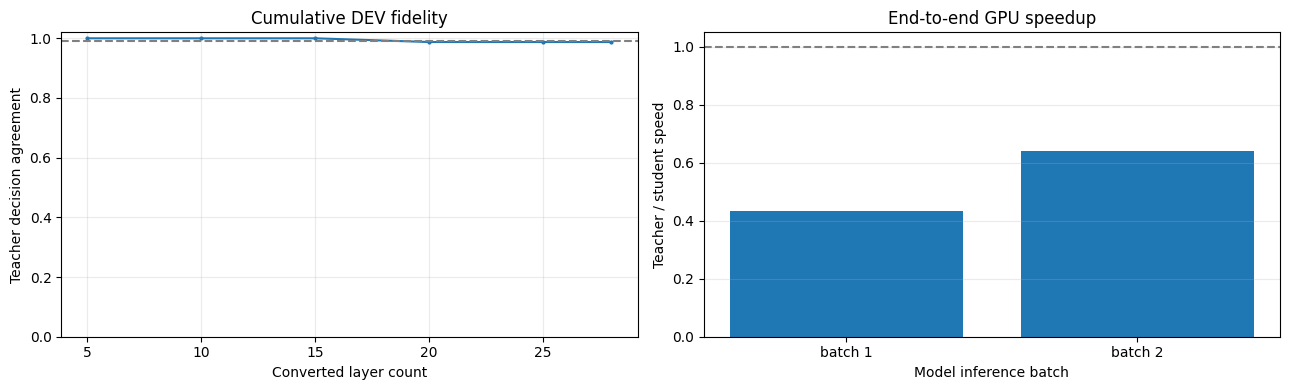

Results: /content/Jev_CeNN/v31_all_attention_report.json /content/Jev_CeNN/v31_all_attention_report.png


In [16]:
#@title 16. Jev_CeNN quality and benchmark visualizations
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(13,4))
if CUMULATIVE:
    axes[0].plot(
        [i+1 for i,x in enumerate(CUMULATIVE) if x["dev"] is not None],
        [x["dev"]["agreement"] for x in CUMULATIVE if x["dev"] is not None],marker=".",ms=4
    )
    axes[0].axhline(TARGET_DEV_AGREEMENT,color="gray",ls="--")
    axes[0].set(xlabel="Converted layer count",ylabel="Teacher decision agreement",
                title="Cumulative DEV fidelity",ylim=(0,1.02))
axes[0].grid(alpha=.25)
axes[1].bar(["batch 1",f"batch {BATCH}"],[p["speedup"] for p in latency])
axes[1].axhline(1,color="gray",ls="--")
axes[1].set(xlabel="Model inference batch",ylabel="Teacher / student speed",
            title="End-to-end GPU speedup")
axes[1].grid(axis="y",alpha=.25)
fig.tight_layout()
figure=OUTPUT_DIR/"v31_all_attention_report.png"
fig.savefig(figure,dpi=160)
plt.show()
print("Results:",report_file,figure)
